# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [8]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [9]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42


## 1. Carga del modelo y del conjunto de prueba

In [10]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print(
    "Modelo:",
    training_metadata.get(
        "champion",
        training_metadata.get("champion_name", "No especificado")
    )
)
print("Test:", X_test.shape)

Modelo: LogisticRegression
Test: (36, 13)


c:\Users\lafon\OneDrive\Escritorio\Talleres IA\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\lafon\OneDrive\Escritorio\Talleres IA\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\lafon\OneDrive\Escritorio\Talleres IA\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipe

## 2. Evaluación final

Accuracy en test: 0.9722
F1 macro en test: 0.9710
\nReporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



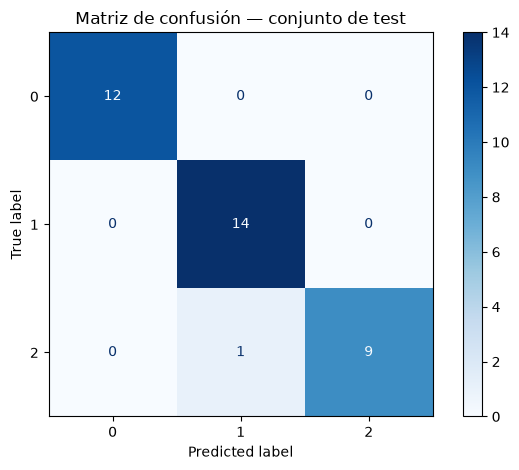

,pred_0,pred_1,pred_2
real_0,12,0,0
real_1,0,14,0
real_2,0,1,9


In [11]:
# Evaluación final: usar el conjunto de test una sola vez.
y_pred = model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
test_f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy en test: {test_accuracy:.4f}")
print(f"F1 macro en test: {test_f1_macro:.4f}")
print("\\nReporte de clasificación:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matriz de confusión — conjunto de test")
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_test, y_pred)
display(pd.DataFrame(cm, index=[f"real_{c}" for c in model.classes_],
                     columns=[f"pred_{c}" for c in model.classes_]))


**Análisis:**

- El accuracy de test es **97,22 %** y el F1 macro es **97,10 %**.
- El accuracy promedio de validación cruzada fue **97,91 %**. El resultado de test es coherente y muy cercano al estimado en validación cruzada.
- La única confusión se da entre una observación de la clase real **2**, predicha como clase **1**. Las clases 0 y 1 se clasificaron correctamente en este conjunto.
- La pequeña diferencia entre validación cruzada y test no aporta evidencia clara de sobreajuste por sí sola. El conjunto de test tiene solo 36 registros, así que la estimación tiene incertidumbre.
- No se reajustan hiperparámetros después de observar test.


## 3. Función de inferencia

In [12]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve predicción y probabilidades si están disponibles."""
    if not isinstance(records, pd.DataFrame):
        raise TypeError("records debe ser un pandas.DataFrame.")

    missing = [col for col in feature_columns if col not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")

    # Ignora columnas adicionales y conserva el orden del entrenamiento.
    X_new = records.loc[:, feature_columns].copy()
    predictions = model.predict(X_new)
    result = pd.DataFrame({"prediction": predictions}, index=records.index)

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_new)
        for i, class_label in enumerate(model.classes_):
            result[f"probability_{class_label}"] = probabilities[:, i]
    return result


## 4. Predicción por lotes

In [13]:
# Simulación de datos nuevos para demostrar la función de inferencia.
new_records = X_test.iloc[:5].copy()
batch_predictions = predict(new_records).reset_index(drop=True)
batch_path = REPORTS_DIR / "batch_predictions.csv"
batch_predictions.to_csv(batch_path, index=False)

display(batch_predictions)
print(f"Predicciones guardadas en: {batch_path}")


,prediction,probability_0,probability_1,probability_2
0,0,0.999671,0.000307,0.000023
1,1,0.007051,0.540423,0.452526
2,0,0.992000,0.007664,0.000336
3,1,0.289967,0.707467,0.002565
4,1,0.033032,0.962313,0.004655


Predicciones guardadas en: c:\Users\lafon\OneDrive\Escritorio\Talleres IA\Semana 06\challenge 3\reports\batch_predictions.csv


## 5. Reporte final

In [14]:
# Guardar métricas finales del modelo campeón
metrics = {
    "model": training_metadata.get("champion_name", training_metadata.get("champion")),
    "selection_metric": training_metadata.get("selection_metric", "accuracy"),
    "accuracy_cv": float(training_metadata["best_cv_accuracy"]),
    "accuracy_test": float(test_accuracy),
    "f1_macro_test": float(test_f1_macro),
    "test_rows": int(len(y_test)),
    "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
    "classes": [int(c) if isinstance(c, (np.integer,)) else c for c in model.classes_],
    "note": "Test se utilizó para evaluación final, no para selección ni ajuste de hiperparámetros."
}
metrics_path = REPORTS_DIR / "test_metrics.json"
metrics_path.write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Métricas guardadas en: {metrics_path}")
print(json.dumps(metrics, indent=2, ensure_ascii=False))


Métricas guardadas en: c:\Users\lafon\OneDrive\Escritorio\Talleres IA\Semana 06\challenge 3\reports\test_metrics.json
{
  "model": "LogisticRegression",
  "selection_metric": "accuracy",
  "accuracy_cv": 0.9790640394088669,
  "accuracy_test": 0.9722222222222222,
  "f1_macro_test": 0.9709618874773139,
  "test_rows": 36,
  "confusion_matrix": [
    [
      12,
      0,
      0
    ],
    [
      0,
      14,
      0
    ],
    [
      0,
      1,
      9
    ]
  ],
  "classes": [
    0,
    1,
    2
  ],
  "note": "Test se utilizó para evaluación final, no para selección ni ajuste de hiperparámetros."
}


In [15]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | Logistic Regression |
| Accuracy CV | 97,91 % |
| Accuracy test | 97,22 % |
| F1 macro test | 97,10 % |
| Clases más confundidas | Una muestra de la clase 2 fue predicha como clase 1 |
| Principal limitación | El test contiene 36 registros; el resultado puede variar con otras muestras |

## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.
